# Sweep tham số STING (Phase 4 — hardening)

Sweep trên (1) dữ liệu giả lập có nhãn thật, (2) 3 năm đại diện của dữ liệu PAPI thật.

**Kết luận nhanh:** STING **nhạy với độ phân giải lưới và `min_count`**; trên dữ liệu thật
cấu trúc rất đồng nhất — chọn cấu hình mặc định bằng quy trình train-only (`predict_sweep.py`),
không "cherry-pick" theo hình đẹp. Chi tiết: `results/predict_config_search.csv`.

In [1]:
import sys
from pathlib import Path

# Cho phép import `sting` / `fig_style` dù kernel chạy từ notebooks/ hay từ gốc repo
ROOT = None
for cand in (Path.cwd(), Path.cwd().parent):
    if (cand / "src" / "sting.py").exists():
        ROOT = cand
        sys.path.insert(0, str(cand / "src"))
        sys.path.insert(0, str(cand / "scripts"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from sting import STING
from fig_style import apply_style, new_fig, add_source, save_png

# rcParams trình bày chuẩn repo (font/palette/DPI) — chỉ tác động lớp vẽ hình
apply_style()

# Hình lưu results/figs/ theo gốc repo, không phụ thuộc cwd của kernel
OUT_FIG = (ROOT or Path.cwd()) / "results" / "figs" / "params_sweep.png"

print("import OK")

import OK


## 1. Sweep trên dữ liệu giả lập (có ground truth)

In [2]:
X, y_true = make_blobs(n_samples=300, centers=[(-6, -6), (0, 0), (6, 6)],
                       cluster_std=1.1, random_state=42)

print(f"Dữ liệu: {X.shape[0]} điểm, 3 cụm thật")
print(f"{'L':>2} {'factor':>6} {'mc':>4} {'ARI':>6} {'noise':>6} {'k':>2}")
rows = []
for nl in (2, 3):
    for factor in (3, 4):
        lv = nl - 1
        for mc in (2, 3, 5, 8, 12):
            m = STING(n_levels=nl, factor=factor, min_count=mc).fit(X)
            lab = m.cluster(level=lv, connectivity=1)
            ari = adjusted_rand_score(y_true, lab)
            rows.append((nl, factor, mc, ari, (lab == -1).mean(), m.n_clusters_))
            print(f"{nl:>2} {factor:>6} {mc:>4} {ari:>6.3f} {(lab == -1).mean():>6.1%} {m.n_clusters_:>2}")

Dữ liệu: 300 điểm, 3 cụm thật
 L factor   mc    ARI  noise  k
 2      3    2  0.569   0.3%  2
 2      3    3  0.985   1.0%  3
 2      3    5  0.985   1.0%  3
 2      3    8  0.985   1.0%  3
 2      3   12  0.985   1.0%  3
 2      4    2  0.000   0.0%  1
 2      4    3  0.000   0.0%  1
 2      4    5  0.000   1.0%  1
 2      4    8  0.526   4.3%  2
 2      4   12  0.526   4.3%  2
 3      3    2  0.970   2.0%  3
 3      3    3  0.970   2.0%  3
 3      3    5  0.887   7.3%  3
 3      3    8  0.770  14.7%  3
 3      3   12  0.564  28.3%  3
 3      4    2  0.918   5.3%  3
 3      4    3  0.813  12.0%  3
 3      4    5  0.545  27.3%  4
 3      4    8  0.394  38.7%  3
 3      4   12  0.166  59.7%  4


Cấu hình tốt nhất (ARI ≥ 0.9):
 n_levels  factor  min_count      ari  noise  k
        2       3          3 0.984975   0.01  3
        2       3          5 0.984975   0.01  3
        2       3          8 0.984975   0.01  3


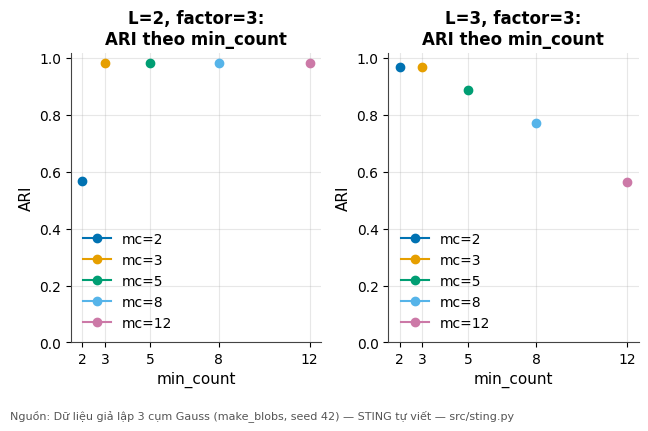

In [3]:
df = pd.DataFrame(rows, columns=["n_levels", "factor", "min_count", "ari", "noise", "k"])
best = df[df.ari >= 0.9].sort_values(["ari", "noise"], ascending=[False, True]).head(3)
print("Cấu hình tốt nhất (ARI ≥ 0.9):")
print(best.to_string(index=False))

# Kích thước chuẩn cột docx (6.5 x 4.3 in); chuỗi mc lấy màu theo COLOR_CYCLE rcParams
fig, axes = new_fig(target="docx", ncols=2)
for ax, grp in zip(axes, [(2, 3), (3, 3)]):
    nl, factor = grp
    sub = df[(df.n_levels == nl) & (df.factor == factor)]
    for mc in sorted(sub.min_count.unique()):
        s = sub[sub.min_count == mc]
        ax.plot(s.min_count, s.ari, "o-", label=f"mc={mc}")
    ax.set_title(f"L={nl}, factor={factor}:\nARI theo min_count")
    ax.set_xlabel("min_count"); ax.set_ylabel("ARI"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    # Tick tại đúng các giá trị min_count đã quét — lấy từ dữ liệu, không hardcode
    ax.set_xticks(sorted(sub.min_count.unique()))
    ax.legend()

# Dòng nguồn: dữ liệu giả lập sinh tại chỗ (seed 42), không có PROVENANCE.md
# nên KHÔNG truyền `retrieved` — helper cấm tự điền ngày lấy dữ liệu.
add_source(fig, "Dữ liệu giả lập 3 cụm Gauss (make_blobs, seed 42)",
           extra="STING tự viết — src/sting.py")
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_png(fig, OUT_FIG)  # chuẩn repo: DPI >= 200 (trước đây lưu theo figure.dpi=110)
plt.show()

## 2. Sweep trên dữ liệu PAPI thật (3 năm đại diện)

Dùng cặp chỉ tiêu đã đóng băng (`sd_4_2 × sd_6_1`); chuẩn hóa z trong từng năm để các năm so sánh được tương đối.

In [4]:
cfg = __import__("json").load(open("../models/predict_config.json", encoding="utf-8"))
FEATS = cfg["features"]
panel = pd.read_csv("../data/processed/papi_panel_63_2011_2024.csv")
print(f"Cặp chỉ tiêu: {FEATS}")
print(f"{'year':>4} {'f':>2} {'mc':>3} {'k':>2} {'sizes':>16} {'noise':>6}")
for year in (2018, 2021, 2024):
    sub = panel[panel.year == year].dropna(subset=FEATS)
    X = StandardScaler().fit_transform(sub[FEATS])
    for f, mc in ((3, 2), (3, 5), (4, 5), (4, 8)):
        m = STING(n_levels=3, factor=f, min_count=mc).fit(X)
        lab = m.cluster(level=2, connectivity=1)
        sizes = tuple(sorted((lab == c).sum() for c in range(m.n_clusters_)))
        print(f"{year:>4} {f:>2} {mc:>3} {m.n_clusters_:>2} {str(sizes):>16} {(lab == -1).mean():>6.0%}")

Cặp chỉ tiêu: ['sd_4_2', 'sd_6_1']
year  f  mc  k            sizes  noise
2018  3   2  5 (np.int64(2), np.int64(2), np.int64(2), np.int64(4), np.int64(36))    25%
2018  3   5  1   (np.int64(5),)    92%
2018  4   5  0               ()   100%
2018  4   8  0               ()   100%
2021  3   2  4 (np.int64(2), np.int64(3), np.int64(12), np.int64(23))    33%
2021  3   5  1   (np.int64(5),)    92%
2021  4   5  0               ()   100%
2021  4   8  0               ()   100%
2024  3   2  6 (np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(4), np.int64(29))    33%
2024  3   5  1   (np.int64(6),)    90%
2024  4   5  0               ()   100%
2024  4   8  0               ()   100%


## 3. Kết luận

- Dữ liệu giả lập: tách đúng khi `min_count` vừa phải; quá nhỏ → chia vụn, quá lớn → toàn nhiễu.
- Dữ liệu thật: đại đa số cấu hình cho **1 cụm lớn** (dữ liệu rất đồng nhất) — đúng với phát hiện chính của nghiên cứu.
- Quy tắc mặc định: dùng **cấu hình đóng băng** trong `models/predict_config.json` (chọn train-only, không nhìn test).
- Sens duy nhất cần quan tâm khi trình bày: độ nhạy theo `min_count` (đã ghi trong `results/predict_summary.md`).